In [1]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data  # Dữ liệu ảnh 8x8 (64 thuộc tính)
y = digits.target  # Nhãn từ 0 đến 9

Họ và tên: Vũ Trương Phi - MSSV: 6451071059
-------------------------------------------------------
Độ chính xác gom cụm (Clustering Accuracy): 79.35%



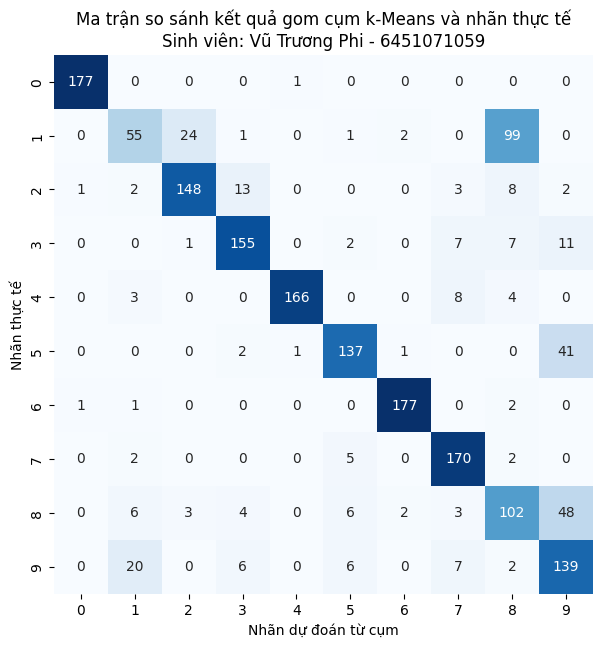

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import mode
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits
from sklearn.metrics import accuracy_score, confusion_matrix

# Thông tin sinh viên
ten = "Vũ Trương Phi"
mssv = "6451071059"
print(f"Họ và tên: {ten} - MSSV: {mssv}")
print("-" * 55)

# 1. Tải dữ liệu MNIST (digits)
digits = load_digits()
X = digits.data
y = digits.target

# 2. Gom cụm bằng k-Means
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)

# 3. Khớp nhãn cụm với nhãn thực tế
labels = np.zeros_like(clusters)
for i in range(10):
  mask = clusters == i
  labels[mask] = mode(y[mask], keepdims=True)[0]

# 4. Tính toán độ chính xác gom cụm
acc = accuracy_score(y, labels)
print(f"Độ chính xác gom cụm (Clustering Accuracy): {acc * 100:.2f}%\n")

# 5. Vẽ ma trận nhầm lẫn trực quan
mat = confusion_matrix(y, labels)
plt.figure(figsize=(9, 7))
sns.heatmap(
    mat,
    square=True,
    annot=True,
    fmt="d",
    cbar=False,
    cmap="Blues",
    xticklabels=digits.target_names,
    yticklabels=digits.target_names,
)
plt.xlabel("Nhãn dự đoán từ cụm")
plt.ylabel("Nhãn thực tế")
plt.title(
    f"Ma trận so sánh kết quả gom cụm k-Means và nhãn thực tế\nSinh viên: {ten} - {mssv}"
)
plt.show()